<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding How The Data Is Distributed**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform Exploratory Data Analysis (EDA). You will examine the structure of the data, visualize key variables, and analyze trends related to developer experience, tools, job satisfaction, and other important aspects.


## Objectives


In this lab you will perform the following:


- Understand the structure of the dataset.

- Perform summary statistics and data visualization.

- Identify trends in developer experience, tools, job satisfaction, and other key variables.


### Install the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn


### Step 1: Import Libraries and Load Data


- Import the `pandas`, `matplotlib.pyplot`, and `seaborn` libraries.


- You will begin with loading the dataset. You can use the pyfetch method if working on JupyterLite. Otherwise, you can use pandas' read_csv() function directly on their local machines or cloud environments.


In [2]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Display the first few rows of the dataset
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 2: Examine the Structure of the Data


- Display the column names, data types, and summary information to understand the data structure.

- Objective: Gain insights into the dataset's shape and available variables.


In [3]:
print("Shape:", df.shape)
print(df.columns.tolist())
df.info()
print(df.dtypes.value_counts())

Shape: (65437, 114)
['ResponseId', 'MainBranch', 'Age', 'Employment', 'RemoteWork', 'Check', 'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline', 'TechDoc', 'YearsCode', 'YearsCodePro', 'DevType', 'OrgSize', 'PurchaseInfluence', 'BuyNewTool', 'BuildvsBuy', 'TechEndorse', 'Country', 'Currency', 'CompTotal', 'LanguageHaveWorkedWith', 'LanguageWantToWorkWith', 'LanguageAdmired', 'DatabaseHaveWorkedWith', 'DatabaseWantToWorkWith', 'DatabaseAdmired', 'PlatformHaveWorkedWith', 'PlatformWantToWorkWith', 'PlatformAdmired', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'EmbeddedHaveWorkedWith', 'EmbeddedWantToWorkWith', 'EmbeddedAdmired', 'MiscTechHaveWorkedWith', 'MiscTechWantToWorkWith', 'MiscTechAdmired', 'ToolsTechHaveWorkedWith', 'ToolsTechWantToWorkWith', 'ToolsTechAdmired', 'NEWCollabToolsHaveWorkedWith', 'NEWCollabToolsWantToWorkWith', 'NEWCollabToolsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'OfficeStackAsyncHaveWorkedWith', 'OfficeStackA

### Step 3: Handle Missing Data


- Identify missing values in the dataset.

- Impute or remove missing values as necessary to ensure data completeness.



In [4]:
# 1. Identify
missing = df.isnull().sum().sort_values(ascending=False)
print(missing.head(15))

# 2. Impute the key categorical columns with the most frequent value
for c in ['RemoteWork', 'Employment', 'EdLevel', 'Country']:
    df[c] = df[c].fillna(df[c].mode()[0])

# 3. Convert YearsCodePro to numbers and impute with the median
df['YearsCodePro'] = pd.to_numeric(
    df['YearsCodePro'].replace({'Less than 1 year': 0.5, 'More than 50 years': 51}),
    errors='coerce')
df['YearsCodePro'] = df['YearsCodePro'].fillna(df['YearsCodePro'].median())

# JobSat is deliberately NOT imputed (about half is missing).
# Imputing it would create a fake spike, so I drop NaN only where I analyze it.
print("Remaining missing in key columns:")
print(df[['RemoteWork', 'Employment', 'EdLevel', 'Country', 'YearsCodePro', 'JobSat']].isnull().sum())

AINextMuch less integrated       64289
AINextLess integrated            63082
AINextNo change                  52939
AINextMuch more integrated       51999
EmbeddedAdmired                  48704
EmbeddedWantToWorkWith           47837
EmbeddedHaveWorkedWith           43223
ConvertedCompYearly              42002
AIToolNot interested in Using    41023
AINextMore integrated            41009
Knowledge_9                      37802
Frequency_3                      37727
Knowledge_8                      37679
ProfessionalTech                 37673
Knowledge_7                      37659
dtype: int64
Remaining missing in key columns:
RemoteWork          0
Employment          0
EdLevel             0
Country             0
YearsCodePro        0
JobSat          36311
dtype: int64


### Step 4: Analyze Key Columns


- Examine key columns such as `Employment`, `JobSat` (Job Satisfaction), and `YearsCodePro` (Professional Coding Experience).

- **Instruction**: Calculate the value counts for each column to understand the distribution of responses.



In [5]:
print(df['Employment'].value_counts().head(10), "\n")
print(df['JobSat'].value_counts(dropna=False).sort_index(), "\n")
print(df['YearsCodePro'].value_counts().sort_index().head(15))

Employment
Employed, full-time                                                         39041
Independent contractor, freelancer, or self-employed                         4846
Student, full-time                                                           4709
Employed, full-time;Independent contractor, freelancer, or self-employed     3557
Not employed, but looking for work                                           2341
Employed, part-time                                                          1266
Student, full-time;Employed, part-time                                       1115
Employed, full-time;Student, full-time                                        897
Employed, full-time;Student, part-time                                        839
Student, full-time;Not employed, but looking for work                         686
Name: count, dtype: int64 

JobSat
0.0       311
1.0       276
2.0       772
3.0      1165
4.0      1130
5.0      1956
6.0      3751
7.0      6379
8.0      7509
9.0     

### Step 5: Visualize Job Satisfaction (Focus on JobSat)


- Create a pie chart or KDE plot to visualize the distribution of `JobSat`.

- Provide an interpretation of the plot, highlighting key trends in job satisfaction.


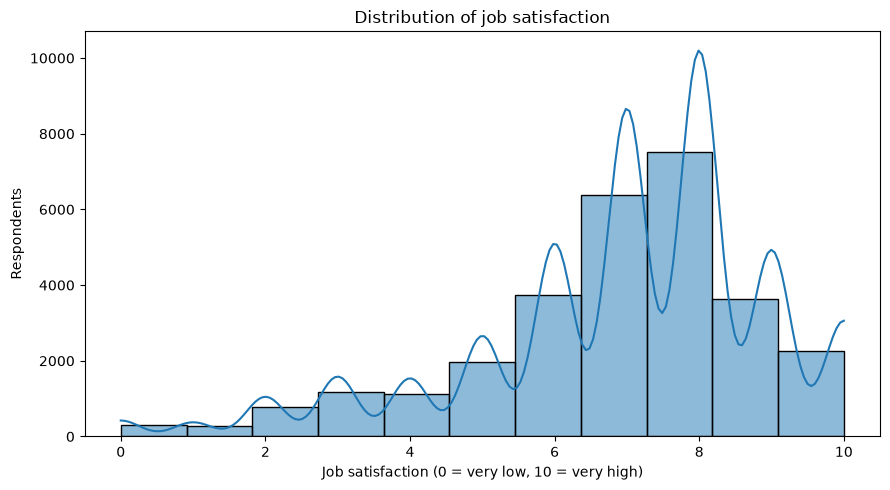

Mean: 6.94 | Median: 7.0 | n = 29126


In [6]:
jobsat = pd.to_numeric(df['JobSat'], errors='coerce').dropna()

plt.figure(figsize=(9, 5))
sns.histplot(jobsat, bins=11, kde=True)
plt.xlabel('Job satisfaction (0 = very low, 10 = very high)')
plt.ylabel('Respondents')
plt.title('Distribution of job satisfaction')
plt.tight_layout()
plt.show()

print("Mean:", round(jobsat.mean(), 2), "| Median:", jobsat.median(), "| n =", len(jobsat))

### Step 6: Programming Languages Analysis


- Compare the frequency of programming languages in `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`.
  
- Visualize the overlap or differences using a Venn diagram or a grouped bar chart.


                         Worked with  Want to work with
LanguageHaveWorkedWith                                 
JavaScript                     37492              23774
HTML/CSS                       31816              20721
Python                         30719              25047
SQL                            30682              22400
TypeScript                     23150              20239
Bash/Shell (all shells)        20412              13744
Java                           18239              10668
C#                             16318              12921
C++                            13827              10873
C                              12184               8275


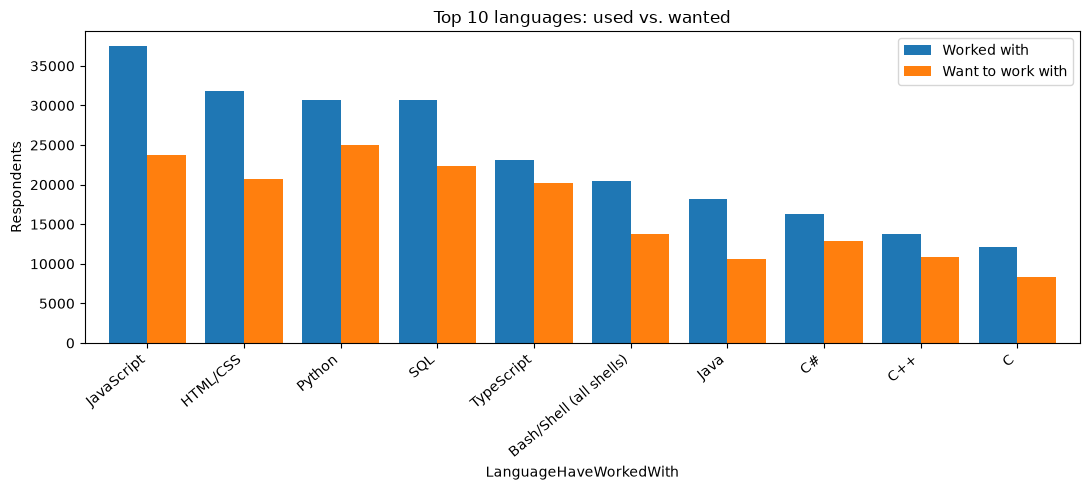

In [7]:
def lang_counts(col):
    return df[col].dropna().str.split(';').explode().str.strip().value_counts()

have = lang_counts('LanguageHaveWorkedWith')
want = lang_counts('LanguageWantToWorkWith')

top = have.head(10).index
compare = pd.DataFrame({'Worked with': have[top], 'Want to work with': want.reindex(top)})
print(compare)

compare.plot(kind='bar', figsize=(11, 5), width=0.8)
plt.ylabel('Respondents')
plt.title('Top 10 languages: used vs. wanted')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

### Step 7: Analyze Remote Work Trends


- Visualize the distribution of RemoteWork by region using a grouped bar chart or heatmap.


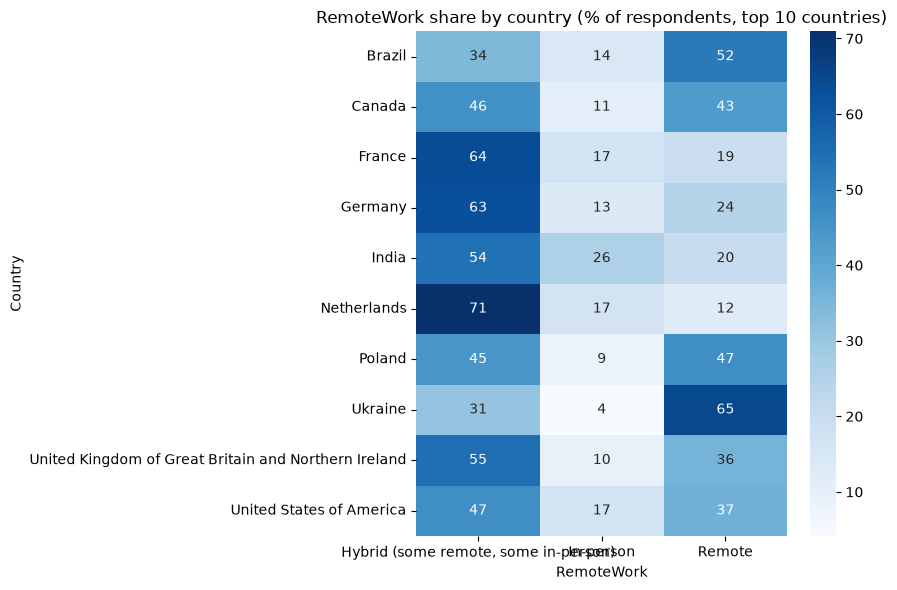

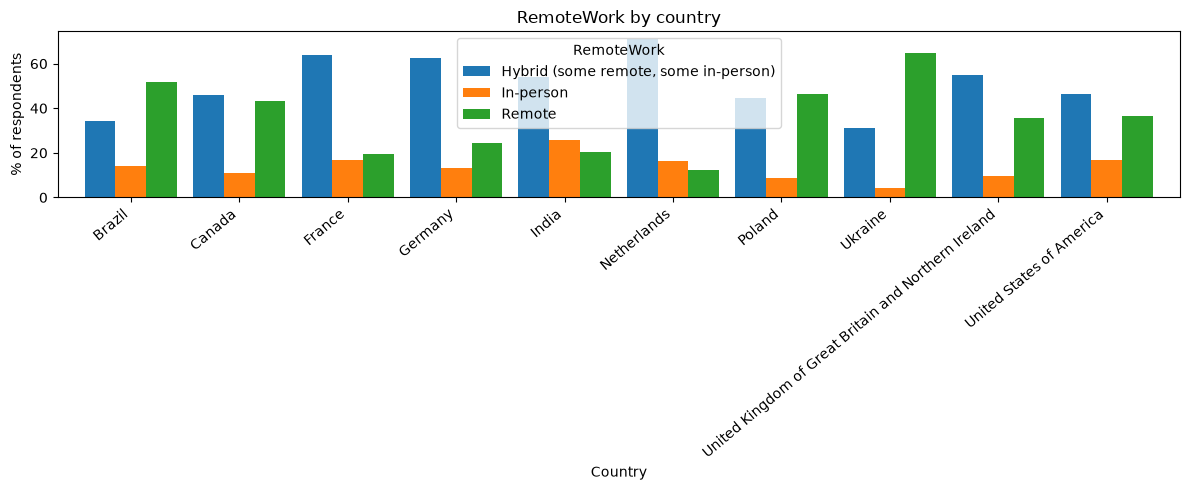

In [8]:
top_countries = df['Country'].value_counts().head(10).index
sub = df[df['Country'].isin(top_countries)]

ct = pd.crosstab(sub['Country'], sub['RemoteWork'], normalize='index') * 100

plt.figure(figsize=(9, 6))
sns.heatmap(ct, annot=True, fmt='.0f', cmap='Blues')
plt.title('RemoteWork share by country (% of respondents, top 10 countries)')
plt.tight_layout()
plt.show()

ct.plot(kind='bar', figsize=(12, 5), width=0.85)
plt.ylabel('% of respondents')
plt.title('RemoteWork by country')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

### Step 8: Correlation between Job Satisfaction and Experience


- Analyze the correlation between overall job satisfaction (`JobSat`) and `YearsCodePro`.
  
- Calculate the Pearson or Spearman correlation coefficient.


Pearson:  0.105
Spearman: 0.118


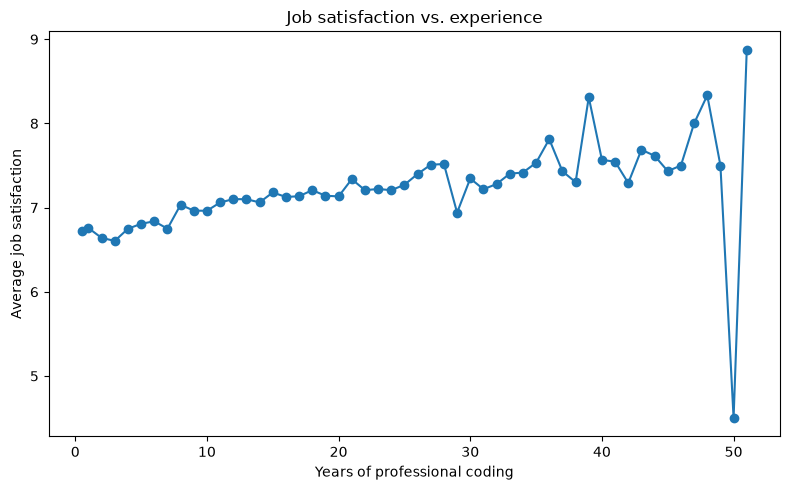

In [12]:
tmp = df[['JobSat', 'YearsCodePro']].copy()
tmp['JobSat'] = pd.to_numeric(tmp['JobSat'], errors='coerce')
tmp = tmp.dropna()

print("Pearson: ", round(tmp['JobSat'].corr(tmp['YearsCodePro']), 3))
print("Spearman:", round(tmp['JobSat'].rank().corr(tmp['YearsCodePro'].rank()), 3))

plt.figure(figsize=(8, 5))
tmp.groupby('YearsCodePro')['JobSat'].mean().plot(marker='o')
plt.xlabel('Years of professional coding')
plt.ylabel('Average job satisfaction')
plt.title('Job satisfaction vs. experience')
plt.tight_layout()
plt.show()

### Step 9: Cross-tabulation Analysis (Employment vs. Education Level)


- Analyze the relationship between employment status (`Employment`) and education level (`EdLevel`).

- **Instruction**: Create a cross-tabulation using `pd.crosstab()` and visualize it with a stacked bar plot if possible.


EdLevel                                             Associate degree  \
Employment                                                             
Employed, full-time                                             1059   
Employed, full-time;Independent contractor, fre...               104   
Independent contractor, freelancer, or self-emp...               143   
Not employed, but looking for work                                74   
Student, full-time                                                81   

EdLevel                                             Bachelor’s degree  \
Employment                                                              
Employed, full-time                                             19322   
Employed, full-time;Independent contractor, fre...               1592   
Independent contractor, freelancer, or self-emp...               1904   
Not employed, but looking for work                               1197   
Student, full-time                                       

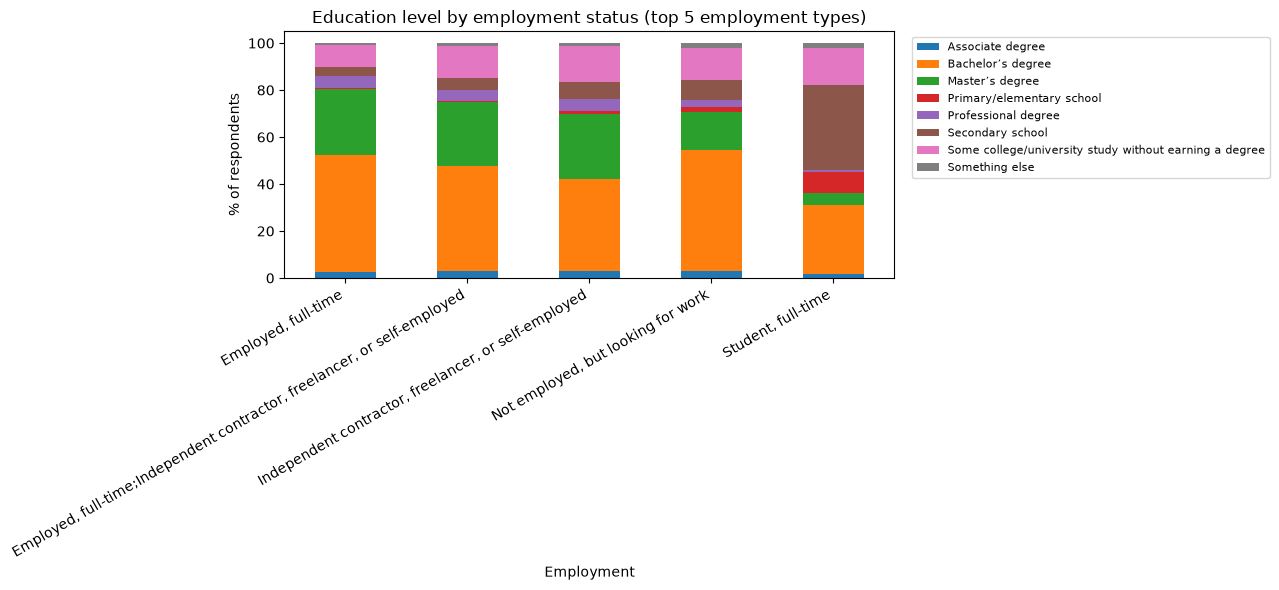

In [10]:
tmp = df.copy()
tmp['EdLevel'] = tmp['EdLevel'].str.split(' \(').str[0]
top_emp = tmp['Employment'].value_counts().head(5).index
tmp = tmp[tmp['Employment'].isin(top_emp)]

ct = pd.crosstab(tmp['Employment'], tmp['EdLevel'])
print(ct)

(ct.div(ct.sum(axis=1), axis=0) * 100).plot(kind='bar', stacked=True, figsize=(12, 6))
plt.ylabel('% of respondents')
plt.title('Education level by employment status (top 5 employment types)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### Step 10: Export Cleaned Data


- Save the cleaned dataset to a new CSV file for further use or sharing.


In [11]:
df.to_csv('cleaned_survey_data_lab13.csv', index=False)
print("Saved:", df.shape)

Saved: (65437, 114)


### Summary:


In this lab, you practiced key skills in exploratory data analysis, including:


- Examining the structure and content of the Stack Overflow survey dataset to understand its variables and data types.

- Identifying and addressing missing data to ensure the dataset's quality and completeness.

- Summarizing and visualizing key variables such as job satisfaction, programming languages, and remote work trends.

- Analyzing relationships in the data using techniques like:
    - Comparing programming languages respondents have worked with versus those they want to work with.
      
    - Exploring remote work preferences by region.

- Investigating correlations between professional coding experience and job satisfaction.

- Performing cross-tabulations to analyze relationships between employment status and education levels.


## Authors:
Ayushi Jain


### Other Contributors:
Rav Ahuja
Lakshmi Holla
Malika


Copyright © IBM Corporation. All rights reserved.
